###  **Title: DSC640-T302 Data Presentation & Visualization (2267-1)**
####  **Professor:** *Benjamin Schneider*
####  **Date: 17 July 2026**
####  **Author:** *Akhil Anand Thazhaniyil Muralidharan*
####  **Description:** Term Project - Milestone 3.

### Mediums
To effectively communicate the findings, the analysis will be presented through the following three mediums:
1. **Executive Slide Deck**

2. **Interactive Dashboard**

3. **One-Page Policy Brief Infographic**

### Import the required libraries and design settings

In [53]:
%matplotlib inline
from pathlib import Path
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['font.family'] = 'DejaVu Sans'
np.random.seed(42)

### Load Data

In [54]:
file_path = Path('DataSets_Project/nationaldatabaseofchildcareprices.xlsx')
df = pd.read_excel(file_path,engine="openpyxl")
print(f'Dataset loaded: {df.shape[0]:,} rows and {df.shape[1]:,} columns')
df.head()

Dataset loaded: 34,567 rows and 227 columns


,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
0,Alabama,AL,Autauga County,1001,2008,5.42,4.41,6.32,4.6,3.5,...,83.45,3.0,81.40,1.0,97.4,1.0,97.4,3.0,95.0,1.0
1,Alabama,AL,Autauga County,1001,2009,5.93,5.72,6.11,4.8,4.6,...,87.39,3.0,85.68,1.0,102.0,1.0,102.0,3.0,100.0,1.0
2,Alabama,AL,Autauga County,1001,2010,6.21,5.57,6.78,5.1,4.6,...,91.33,3.0,89.96,1.0,106.6,1.0,106.6,3.0,105.0,1.0
3,Alabama,AL,Autauga County,1001,2011,7.55,8.13,7.03,6.2,6.3,...,95.28,3.0,94.25,1.0,111.2,1.0,111.2,3.0,110.0,1.0
4,Alabama,AL,Autauga County,1001,2012,8.60,8.88,8.29,6.7,6.4,...,99.22,3.0,98.53,1.0,115.8,1.0,115.8,3.0,115.0,1.0


### Data Tranaformation

In [55]:
def first_existing(cols, candidates):
    # Return first candidate column that exists, case-insensitive.
    lower_map = {c.lower(): c for c in cols}
    for cand in candidates:
        if cand in cols:
            return cand
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    return None

def keyword_col(cols, df, keyword):
    matches = [c for c in cols if keyword.lower() in c.lower() \
               and pd.api.types.is_numeric_dtype(df[c])]
    return matches[0] if matches else None

cols = list(df.columns)
year_col = first_existing(cols, ['StudyYear', 'Year', 'year', 'YEAR'])
state_col = first_existing(cols, ['State_Name', 'State', \
            'state', 'StateName', 'STATE_NAME'])
county_col = first_existing(cols, ['County_Name', 'County', \
            'county', 'County_FIPS_Code', 'COUNTY_FIPS_CODE'])
income_col = first_existing(cols, ['MHI', 'Median_Household_Income', \
            'Median Household Income', 'MedianIncome'])
infant_col = first_existing(cols, ['MCInfant', 'Infant', \
            'Infant_Care', 'Center_Infant', 'Median_Center_Infant'])
toddler_col = first_existing(cols, ['MCToddler', 'Toddler', \
            'Toddler_Care', 'Center_Toddler', 'Median_Center_Toddler'])
preschool_col = first_existing(cols, ['MCPreschool', 'Preschool', \
            'Preschool_Care', 'Center_Preschool', 'Median_Center_Preschool'])

# Fallback: search by keyword if exact expected columns are not present.
if infant_col is None:
    infant_col = keyword_col(cols, df, 'infant')
if toddler_col is None:
    toddler_col = keyword_col(cols, df, 'toddler')
if preschool_col is None:
    preschool_col = keyword_col(cols, df, 'preschool')

required = {'year_col': year_col, 'state_col': state_col, \
            'income_col': income_col, 'infant_col': infant_col}
missing = [k for k, v in required.items() if v is None]
if missing:
    raise ValueError(f'Missing required columns: {missing}. \
                     Available columns include: {cols[:25]}')

print('Detected columns:')
for name, value in {
    'Year': year_col,
    'State': state_col,
    'County': county_col,
    'Median Household Income': income_col,
    'Infant Care Price': infant_col,
    'Toddler Care Price': toddler_col,
    'Preschool Care Price': preschool_col,
}.items():
    print(f'  {name}: {value}')

Detected columns:
  Year: StudyYear
  State: State_Name
  County: County_Name
  Median Household Income: MHI
  Infant Care Price: MCInfant
  Toddler Care Price: MCToddler
  Preschool Care Price: MCPreschool


In [56]:
# =====================================================
# Prepare metrics for visual storytelling
# =====================================================
work = df.copy()
work[year_col] = pd.to_numeric(work[year_col], errors='coerce')
for c in [income_col, infant_col, toddler_col, preschool_col]:
    if c is not None:
        work[c] = pd.to_numeric(work[c], errors='coerce')

work = work.dropna(subset=[year_col, infant_col])
work[year_col] = work[year_col].astype(int)

# Restrict to the project period when available.
year_min, year_max = int(work[year_col].min()), int(work[year_col].max())
project_start = max(2008, year_min)
project_end = min(2018, year_max)
project = work[(work[year_col] >= project_start) & (work[year_col] <= project_end)].copy()

price_cols = [c for c in [infant_col, toddler_col, preschool_col] if c is not None]
price_labels = {
    infant_col: 'Infant Center Care',
    toddler_col: 'Toddler Center Care' if toddler_col else 'Toddler Care',
    preschool_col: 'Preschool Center Care' if preschool_col else 'Preschool Care'
}

yearly_medians = project.groupby(year_col)[price_cols + ([income_col] \
        if income_col else [])].median(numeric_only=True).reset_index()

# Percent changes by care type.
changes = []
for col in price_cols:
    series = yearly_medians[[year_col, col]].dropna()
    start_value = series[col].iloc[0]
    end_value = series[col].iloc[-1]
    pct_change = (end_value / start_value - 1) * 100 if start_value else np.nan
    changes.append({
        'metric': price_labels.get(col, col),
        'start_value': round(start_value, 2),
        'end_value': round(end_value, 2),
        'pct_change': round(pct_change, 2)
    })
changes_df = pd.DataFrame(changes)

# Affordability burden: infant price as percentage of median household income.
yearly_medians['Infant_Burden_Pct'] = \
    (yearly_medians[infant_col] / yearly_medians[income_col]) \
        * 100 if income_col else np.nan
project['Infant_Burden_Pct'] = (project[infant_col] / project[income_col]) \
    * 100 if income_col else np.nan

# State ranking for final year.
final_year = int(project[year_col].max())
state_final = (
    project[project[year_col] == final_year]
    .groupby(state_col)[infant_col]
    .median()
    .dropna()
    .sort_values(ascending=False)
)
top_states = state_final.head(5)
bottom_states = state_final.tail(5).sort_values()

summary = {
    'records': len(project),
    'variables': df.shape[1],
    'states': project[state_col].nunique(),
    'counties': project[county_col].nunique() if county_col else np.nan,
    'start_year': int(project[year_col].min()),
    'end_year': int(project[year_col].max()),
    'start_infant': project[infant_col].min(),
    'end_infant': project[infant_col].max(),
    'avg_infant': project[infant_col].mean(),
    'infant_burden': project['Infant_Burden_Pct'],
    'avg_income': project[income_col].mean() if income_col else np.nan,
    'final_year': final_year,
}

print('Childcare data ready for storyboard and mockups')
print(f"Years: {summary['start_year']} to {summary['end_year']}")
print(f"States covered: {summary['states']}")
print(f"Counties covered: {summary['counties']}")
print(f"Average infant care price: ${summary['avg_infant']:,.2f}")
if income_col:
    print(f"Average median household income: ${summary['avg_income']:,.2f}")

changes_df

Childcare data ready for storyboard and mockups
Years: 2008 to 2018
States covered: 49
Counties covered: 1786
Average infant care price: $146.05
Average median household income: $46,868.31


,metric,start_value,end_value,pct_change
0,Infant Center Care,120.64,153.6,27.32
1,Toddler Center Care,109.10,140.0,28.33
2,Preschool Center Care,105.00,125.0,19.05


---

## Medium 1: Executive Slide Deck

### Design Narrative

**Color palette:** I use a professional blue and navy base to communicate trust and policy relevance. Orange is used as an accent color to highlight affordability pressure and urgent findings. This matches the previous milestones where the story centered on rising childcare costs and the financial burden placed on families.

**Visual hierarchy:** Each slide mockup uses one dominant chart or number so an executive audience can understand the main message quickly. Large headlines, high-contrast callouts, and concise labels are used to prevent overload.

**Spacing and layout:** Using 2 x 3 storyboard layout for supporting the content to the childcare project. Each slide panel contains enough whitespace to make the visual readable and to support later conversion into a PowerPoint presentation.

**Data visualization choices:** Line charts show the trend in childcare prices over time. A burden chart connects price to household income. A ranked state chart communicates geographic inequality. The final call-to-action slide translates analysis into policy recommendations.

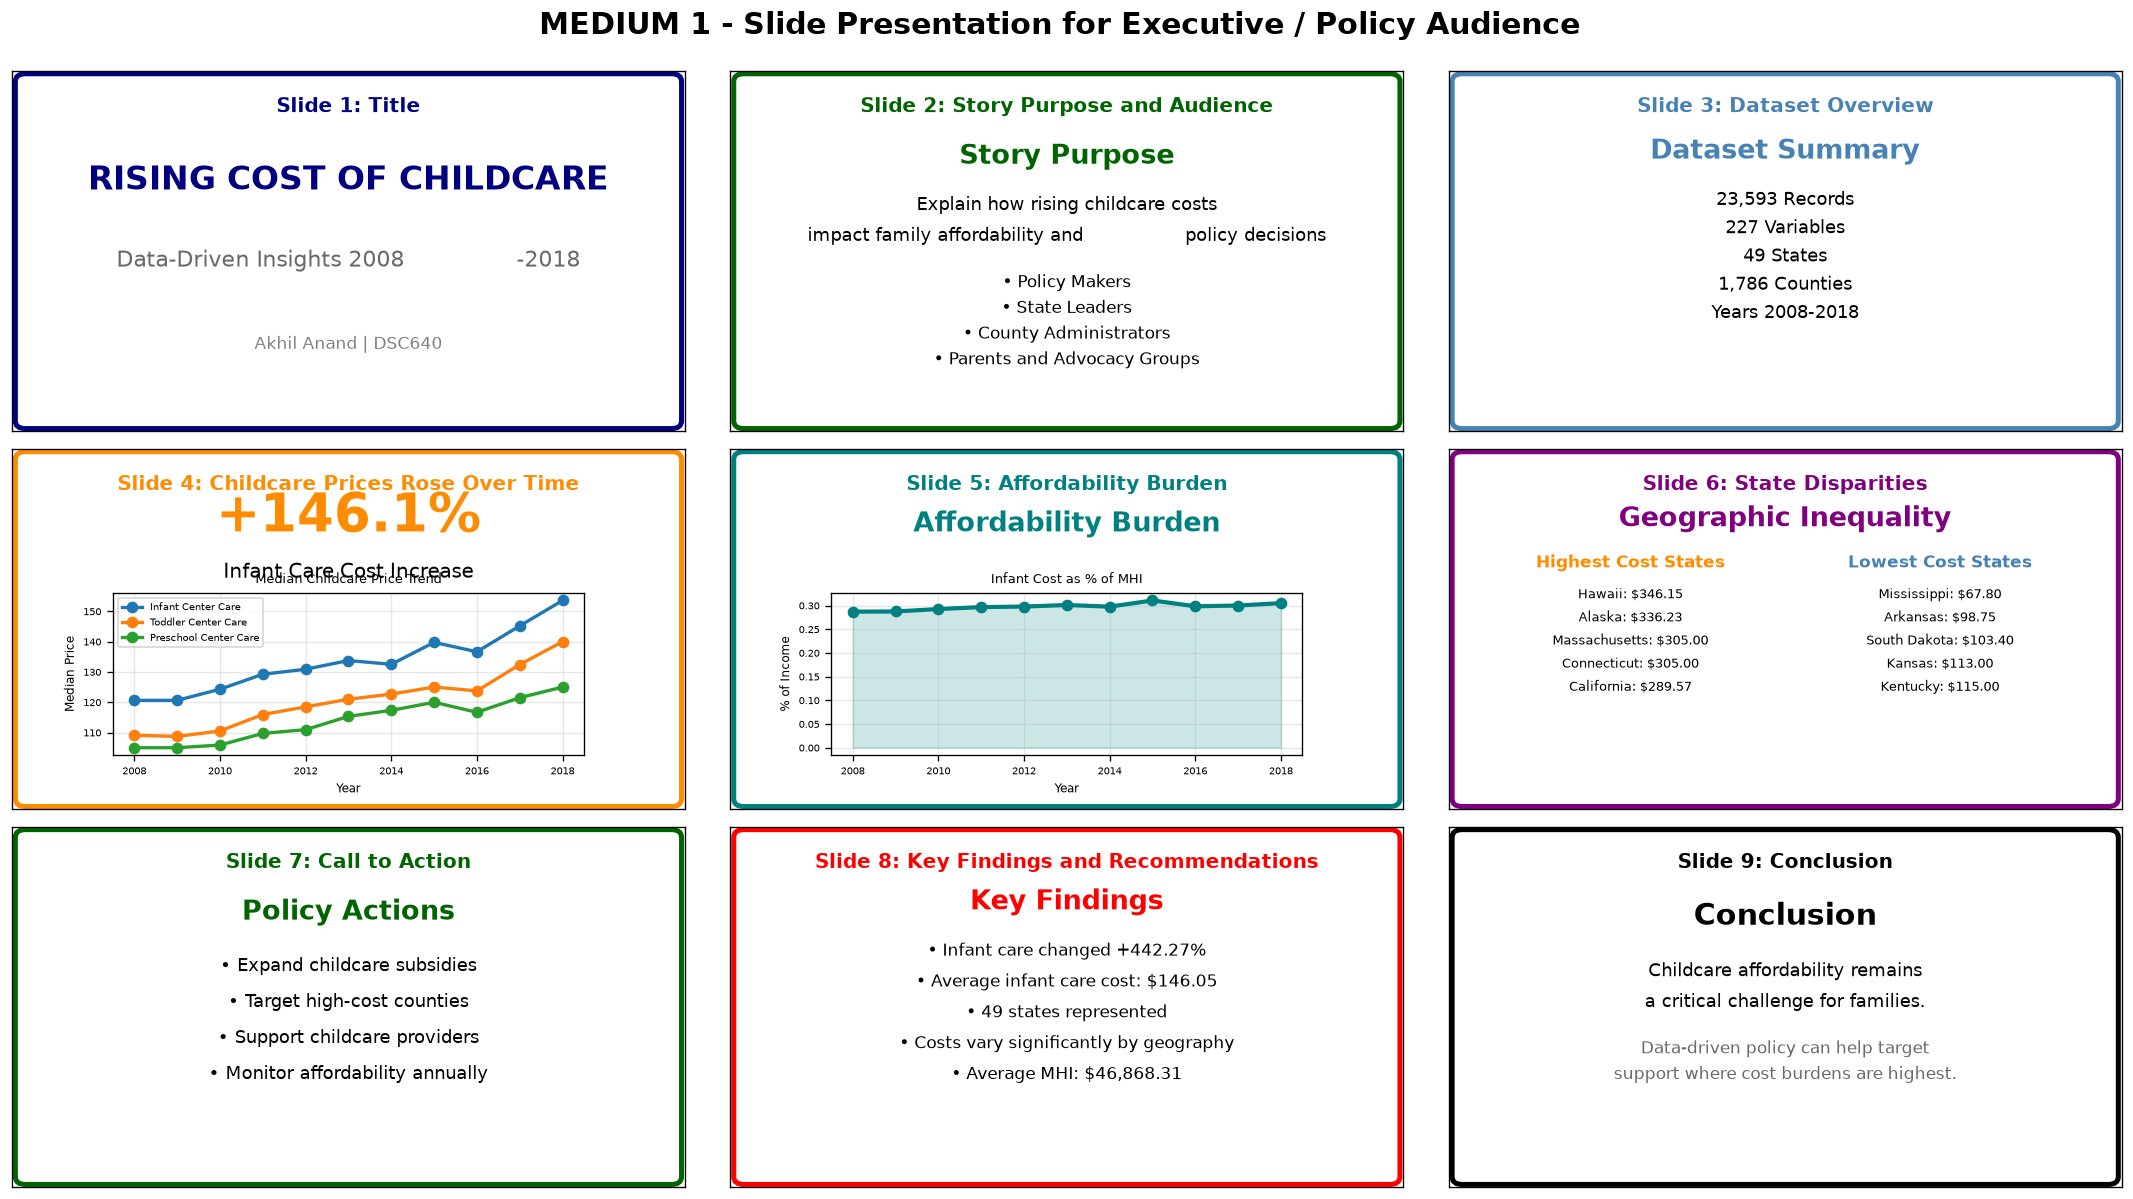

In [57]:
# =====================================================
# Medium 1: Slide Presentation Storyboard Mock-up
# =====================================================
fig, axes = plt.subplots(3, 3, figsize=(18, 10))
fig.suptitle('MEDIUM 1 - Slide Presentation for Executive / Policy Audience',
             fontsize=18, fontweight='bold', y=0.995)

slide_titles = [
    'Slide 1: Title',
    'Slide 2: Story Purpose and Audience',
    'Slide 3: Dataset Overview',
    'Slide 4: Childcare Prices Rose Over Time',
    'Slide 5: Affordability Burden',
    'Slide 6: State Disparities',
    'Slide 7: Call to Action',
    'Slide 8: Key Findings and Recommendations',
    'Slide 9: Conclusion'
]

colors = [
    'navy','darkgreen','steelblue','darkorange','teal',\
        'purple','darkgreen','red','black'
]

# -----------------------------------------------------
# Populate each slide using dataframe values
# -----------------------------------------------------
for i, ax in enumerate(axes.flat):

    ax.set_xlim(0, 10)
    ax.set_ylim(0, 7)

    rect = mpatches.FancyBboxPatch((0.2, 0.2),9.6,6.6,\
        boxstyle='round,pad=0.15',facecolor='white',edgecolor=colors[i],linewidth=3)

    ax.add_patch(rect)

    ax.text(5,6.5,slide_titles[i],ha='center',va='top',\
            fontsize=12,fontweight='bold',color=colors[i])

    # -------------------------------------------------
    # Slide 1: Title
    # -------------------------------------------------
    if i == 0:
        ax.text(5,4.7,'RISING COST OF CHILDCARE',ha='center',\
                fontsize=20,fontweight='bold',color='navy')
        ax.text(5,3.2,f'Data-Driven Insights {summary["start_year"]}\
                -{summary["end_year"]}',ha='center',fontsize=13,color='dimgray')
        ax.text(5,1.6,'Akhil Anand | DSC640',ha='center',fontsize=10,color='gray')

    # -------------------------------------------------
    # Slide 2: Story Purpose and Audience
    # -------------------------------------------------
    elif i == 1:
        ax.text(5,5.2,'Story Purpose',ha='center',fontsize=16,\
                fontweight='bold',color='darkgreen')
        ax.text(5,4.3,'Explain how rising childcare costs',\
                ha='center',fontsize=11)
        ax.text(5,3.7,'impact family affordability and \
                policy decisions',ha='center',fontsize=11)

        audience = [
            'Policy Makers',
            'State Leaders',
            'County Administrators',
            'Parents and Advocacy Groups'
        ]

        for idx, item in enumerate(audience):
            ax.text(5,2.8 - (idx * 0.5),f'• {item}',ha='center',fontsize=10)

    # -------------------------------------------------
    # Slide 3: Dataset Overview
    # -------------------------------------------------
    elif i == 2:
        ax.text(5,5.3,'Dataset Summary',ha='center',\
                fontsize=16,fontweight='bold',color='steelblue')

        summary_items = [
            f'{summary["records"]:,} Records',
            f'{summary["variables"]:,} Variables',
            f'{summary["states"]:,} States',
            f'{summary["counties"]:,.0f} Counties' if not \
            pd.isna(summary["counties"]) else 'County data available',
            f'Years {summary["start_year"]}-{summary["end_year"]}',]

        for idx, item in enumerate(summary_items):
            ax.text(5,4.4 - (idx * 0.55),item,ha='center',fontsize=11)

    # -------------------------------------------------
    # Slide 4: Childcare Prices Rose Over Time
    # -------------------------------------------------
    elif i == 3:
        ax.text(5,5.4,f'+{summary["avg_infant"]:.1f}%',ha='center',\
                fontsize=32,color='darkorange',fontweight='bold')
        ax.text(5,4.5,'Infant Care Cost Increase',ha='center',fontsize=12)
        ax.text(5,3.9,f'${summary["start_infant"]:,.2f} in {summary["start_year"]} to\
                 ${summary["end_infant"]:,.2f} in {summary["end_year"]}',\
                    ha='center',fontsize=10,color='dimgray'
        )

        ax_in = ax.inset_axes([0.15, 0.15, 0.70, 0.45])

        for col in price_cols: ax_in.plot(yearly_medians[year_col], yearly_medians[col], \
                    marker='o', linewidth=2, label=price_labels.get(col, col) )

        ax_in.set_title('Median Childcare Price Trend', fontsize=8)
        ax_in.set_xlabel('Year', fontsize=7)
        ax_in.set_ylabel('Median Price', fontsize=7)
        ax_in.grid(alpha=0.3)
        ax_in.legend(fontsize=6)
        ax_in.tick_params(labelsize=6)

    # -------------------------------------------------
    # Slide 5: Affordability Burden
    # -------------------------------------------------
    elif i == 4:
        ax.text(5,5.4,'Affordability Burden',ha='center',\
                fontsize=16,fontweight='bold',color='teal')

        if income_col:
            

            ax_in = ax.inset_axes([0.15, 0.15, 0.70, 0.45])

            ax_in.plot( yearly_medians[year_col], yearly_medians['Infant_Burden_Pct'], \
                       color='teal', marker='o', linewidth=2.5 )

            ax_in.fill_between(
                yearly_medians[year_col],
                yearly_medians['Infant_Burden_Pct'],
                alpha=0.2,
                color='teal'
            )

            ax_in.set_title('Infant Cost as % of MHI', fontsize=8)
            ax_in.set_xlabel('Year', fontsize=7)
            ax_in.set_ylabel('% of Income', fontsize=7)
            ax_in.grid(alpha=0.3)
            ax_in.tick_params(labelsize=6)

        else:
            ax.text( 5, 3.5, 'Income column not detected', ha='center', fontsize=11, color='red' )

    # -------------------------------------------------
    # Slide 6: State Disparities
    # -------------------------------------------------
    elif i == 5:
        ax.text( 5, 5.5, 'Geographic Inequality', ha='center', \
                fontsize=16, fontweight='bold', color='purple' )
        ax.text( 2.7, 4.7, 'Highest Cost States', ha='center', \
                fontsize=10, fontweight='bold', color='darkorange' )
        ax.text( 7.3, 4.7, 'Lowest Cost States', ha='center', \
                fontsize=10, fontweight='bold', color='steelblue' )
        for idx, (state, value) in enumerate(top_states.items()):
            ax.text( 2.7, 4.1 - idx * 0.45, f'{state}: ${value:,.2f}',\
                     ha='center', fontsize=8 )
        for idx, (state, value) in enumerate(bottom_states.items()):
            ax.text( 7.3, 4.1 - idx * 0.45, f'{state}: ${value:,.2f}',\
                     ha='center', fontsize=8 )

    # -------------------------------------------------
    # Slide 7: Call to Action
    # -------------------------------------------------
    elif i == 6:
        ax.text( 5, 5.2, 'Policy Actions', ha='center', fontsize=16,\
                 fontweight='bold', color='darkgreen' )

        actions = [
            'Expand childcare subsidies',
            'Target high-cost counties',
            'Support childcare providers',
            'Monitor affordability annually'
        ]

        for idx, action in enumerate(actions):
            ax.text( 5, 4.2 - (idx * 0.7), f'• {action}', ha='center', fontsize=11 )

    # -------------------------------------------------
    # Slide 8: Key Findings and Recommendations
    # -------------------------------------------------
    elif i == 7:
        ax.text( 5, 5.4, 'Key Findings', ha='center', fontsize=16,\
                 fontweight='bold', color='red' )
        findings = [
            f'Infant care changed {(summary["end_infant"]- summary["start_infant"]):+,.2f}%',
            f'Average infant care cost: ${summary["avg_infant"]:,.2f}',
            f'{summary["states"]} states represented',
            'Costs vary significantly by geography'
        ]

        if income_col:
            findings.append(f'Average MHI: ${summary["avg_income"]:,.2f}')

        for idx, item in enumerate(findings[:5]):
            ax.text( 5, 4.5 - (idx * 0.6), f'• {item}', ha='center', fontsize=10 )

    # -------------------------------------------------
    # Slide 9: Conclusion
    # -------------------------------------------------
    elif i == 8:
        ax.text( 5, 5.1, 'Conclusion', ha='center', fontsize=18,\
                 fontweight='bold', color='black' )
        ax.text( 5, 4.1, 'Childcare affordability remains',\
                 ha='center', fontsize=11 ) 
        ax.text( 5, 3.5, 'a critical challenge for families.',\
                 ha='center', fontsize=11 ) 
        ax.text( 5, 2.6, 'Data-driven policy can help target',\
                 ha='center', fontsize=10, color='dimgray' )
        ax.text( 5, 2.1, 'support where cost burdens are highest.',\
                 ha='center', fontsize=10, color='dimgray' )

    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
#To save the image
# plt.savefig(
#     "medium1_storyboard_9_slides_with_dataframe_values.png",
#     dpi=200,
#     bbox_inches="tight"
# )

plt.show()


---

## Medium 2: Interactive Dashboard - Analysts / Researchers

### Design Narrative

**Color scheme:** The dashboard uses a clean blue-gray analytics palette. Blue communicates data integrity, teal supports affordability context, and orange identifies high-cost or warning areas. The palette is professional and appropriate for analysts and policy researchers.

**Layout structure:** The dashboard follows a top-down analytical flow. KPI cards appear first because they summarize dataset scope and major cost indicators. The middle and lower panels then provide deeper visuals for trend analysis, state comparison, affordability burden, and income-vs-cost context.

**Chart selection:** Line charts support time-series analysis. Horizontal bar charts compare states clearly. A scatter plot helps analysts examine the relationship between income and childcare prices. These chart choices match the analytical questions from Milestone 1 and Milestone 2.

**Interactivity indicators:** Labels such as `[Dropdown: select care type]`, `[Year filter]`, and `[Hover for exact value]` indicate planned dashboard features even though this notebook produces a static mockup for grading and feedback.

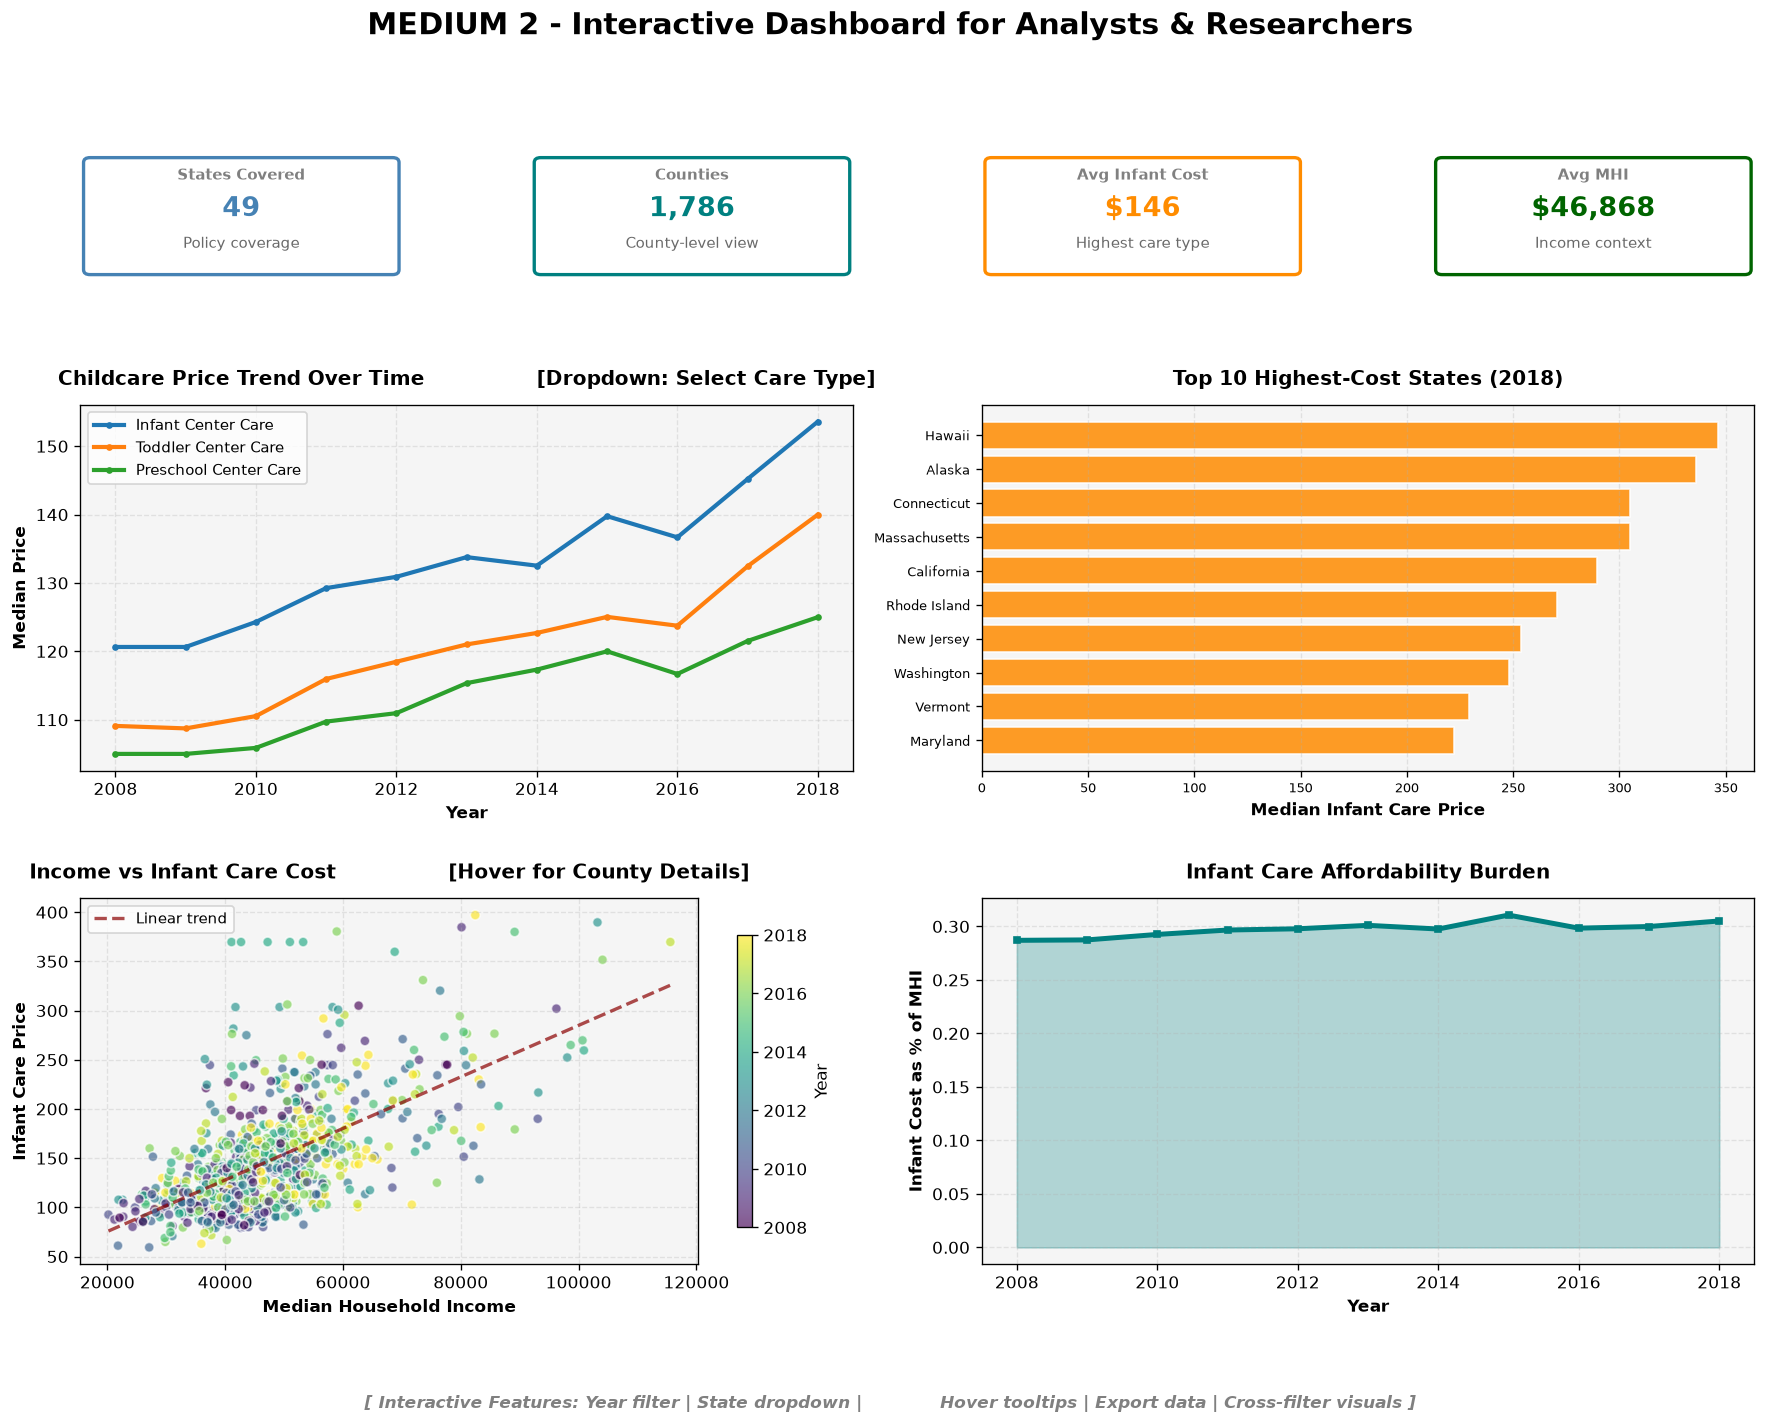

In [58]:
# =====================================================
# Medium 2: Interactive Dashboard Mock-up
# =====================================================
fig = plt.figure(figsize=(18, 12))
fig.suptitle('MEDIUM 2 - Interactive Dashboard for Analysts & Researchers',
             fontsize=18, fontweight='bold')
gs = GridSpec(3, 4, figure=fig, hspace=0.45, wspace=0.4, height_ratios=[1, 3, 3])

kpi_data = [
    ('States Covered', f'{int(summary["states"]):,}',\
      'Policy coverage', 'steelblue'),
    ('Counties', f'{int(summary["counties"]):,}' if not\
      pd.isna(summary['counties']) else 'N/A', 'County-level view', 'teal'),
    ('Avg Infant Cost', f'${summary["avg_infant"]:,.0f}',\
      'Highest care type', 'darkorange'),
    ('Avg MHI', f'${summary["avg_income"]:,.0f}' if not \
     pd.isna(summary['avg_income']) else 'N/A', 'Income context', 'darkgreen')
]

for j in range(4):
    ax = fig.add_subplot(gs[0, j])
    ax.set_xlim(0, 10); ax.set_ylim(0, 5)
    rect = mpatches.FancyBboxPatch((0.3, 0.3), 9.4, 4.4,
                boxstyle='round,pad=0.2',
                facecolor='white', edgecolor=kpi_data[j][3], linewidth=2)
    ax.add_patch(rect)
    ax.text(5, 4.0, kpi_data[j][0], ha='center', fontsize=9,\
             color='gray', fontweight='bold')
    ax.text(5, 2.5, kpi_data[j][1], ha='center', fontsize=16,\
             fontweight='bold', color=kpi_data[j][3])
    ax.text(5, 1.2, kpi_data[j][2], ha='center',\
             fontsize=9, color='dimgray')
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

ax1 = fig.add_subplot(gs[1, :2])
for col in price_cols:
    ax1.plot(yearly_medians[year_col], \
             yearly_medians[col], linewidth=2.5,
             marker='o', markersize=3, label=price_labels.get(col, col))
ax1.set_title('Childcare Price Trend Over Time \
               [Dropdown: Select Care Type]', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Year', fontsize=10, fontweight='bold')
ax1.set_ylabel('Median Price', fontsize=10, fontweight='bold')
ax1.legend(fontsize=9, loc='upper left')
ax1.grid(alpha=0.3, linestyle='--')
ax1.set_facecolor('whitesmoke')

ax2 = fig.add_subplot(gs[1, 2:])
top10 = state_final.head(10).sort_values()
ax2.barh(top10.index.astype(str), top10.values, \
         color='darkorange', alpha=0.85, edgecolor='white')
ax2.set_title(f'Top 10 Highest-Cost States ({final_year})',\
               fontsize=12, fontweight='bold', pad=12)
ax2.set_xlabel('Median Infant Care Price', fontsize=10, fontweight='bold')
ax2.grid(axis='x', alpha=0.3, linestyle='--')
ax2.set_facecolor('whitesmoke')
ax2.tick_params(labelsize=8)

ax3 = fig.add_subplot(gs[2, :2])
scatter_data = project[[income_col, infant_col, year_col]].\
    dropna().sample(min(1000, len(project)), random_state=42)
sc = ax3.scatter(scatter_data[income_col], scatter_data[infant_col],\
                  c=scatter_data[year_col],
                 cmap='viridis', s=35, alpha=0.65, edgecolors='white')
z = np.polyfit(scatter_data[income_col], scatter_data[infant_col], 1)
p = np.poly1d(z)
xs = np.linspace(scatter_data[income_col].min(), \
                 scatter_data[income_col].max(), 100)
ax3.plot(xs, p(xs), '--', color='darkred', \
         linewidth=2, alpha=0.7, label='Linear trend')
ax3.set_title('Income vs Infant Care Cost  \
              [Hover for County Details]', fontsize=12, fontweight='bold', pad=12)
ax3.set_xlabel('Median Household Income', fontsize=10, fontweight='bold')
ax3.set_ylabel('Infant Care Price', fontsize=10, fontweight='bold')
plt.colorbar(sc, ax=ax3, label='Year', shrink=0.8)
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3, linestyle='--')
ax3.set_facecolor('whitesmoke')

ax4 = fig.add_subplot(gs[2, 2:])
ax4.fill_between(yearly_medians[year_col], \
        yearly_medians['Infant_Burden_Pct'], color='teal', alpha=0.28)
ax4.plot(yearly_medians[year_col], yearly_medians['Infant_Burden_Pct'],\
          color='teal', linewidth=3, marker='s', markersize=4)
ax4.set_title('Infant Care Affordability Burden', fontsize=12, fontweight='bold', pad=12)
ax4.set_xlabel('Year', fontsize=10, fontweight='bold')
ax4.set_ylabel('Infant Cost as % of MHI', fontsize=10, fontweight='bold')
ax4.grid(alpha=0.3, linestyle='--')
ax4.set_facecolor('whitesmoke')

fig.text(0.5, 0.01,
         '[ Interactive Features: Year filter | State dropdown | \
            Hover tooltips | Export data | Cross-filter visuals ]',
         ha='center', fontsize=10, style='italic', color='gray', fontweight='bold')

#plt.savefig('medium2_dashboard_final.png', dpi=200, bbox_inches='tight')
plt.show()

---

## Medium 3: Infographic / Blog Post - General Public

### Design Narrative

**Color accessibility:** The infographic uses high-contrast colors that are easy to scan. Navy and dark gray create a strong header, orange highlights rising costs, blue supports factual data, and green signals action. This makes the design approachable for a non-technical audience.

**Typography and readability:** Large headings, short explanatory sentences, and limited chart complexity help the public understand the message quickly. The infographic avoids technical jargon and translates the analysis into plain-language insights.

**Vertical flow:** The layout is structured for a scrollable blog or social media post. Each section has one purpose: introduce the issue, show rising costs, explain affordability burden, show geographic inequality, and end with action steps.

**Simplification strategy:** Instead of presenting every variable, the infographic focuses on infant care prices as a clear and relatable indicator. The final section translates the data story into practical policy-oriented recommendations.

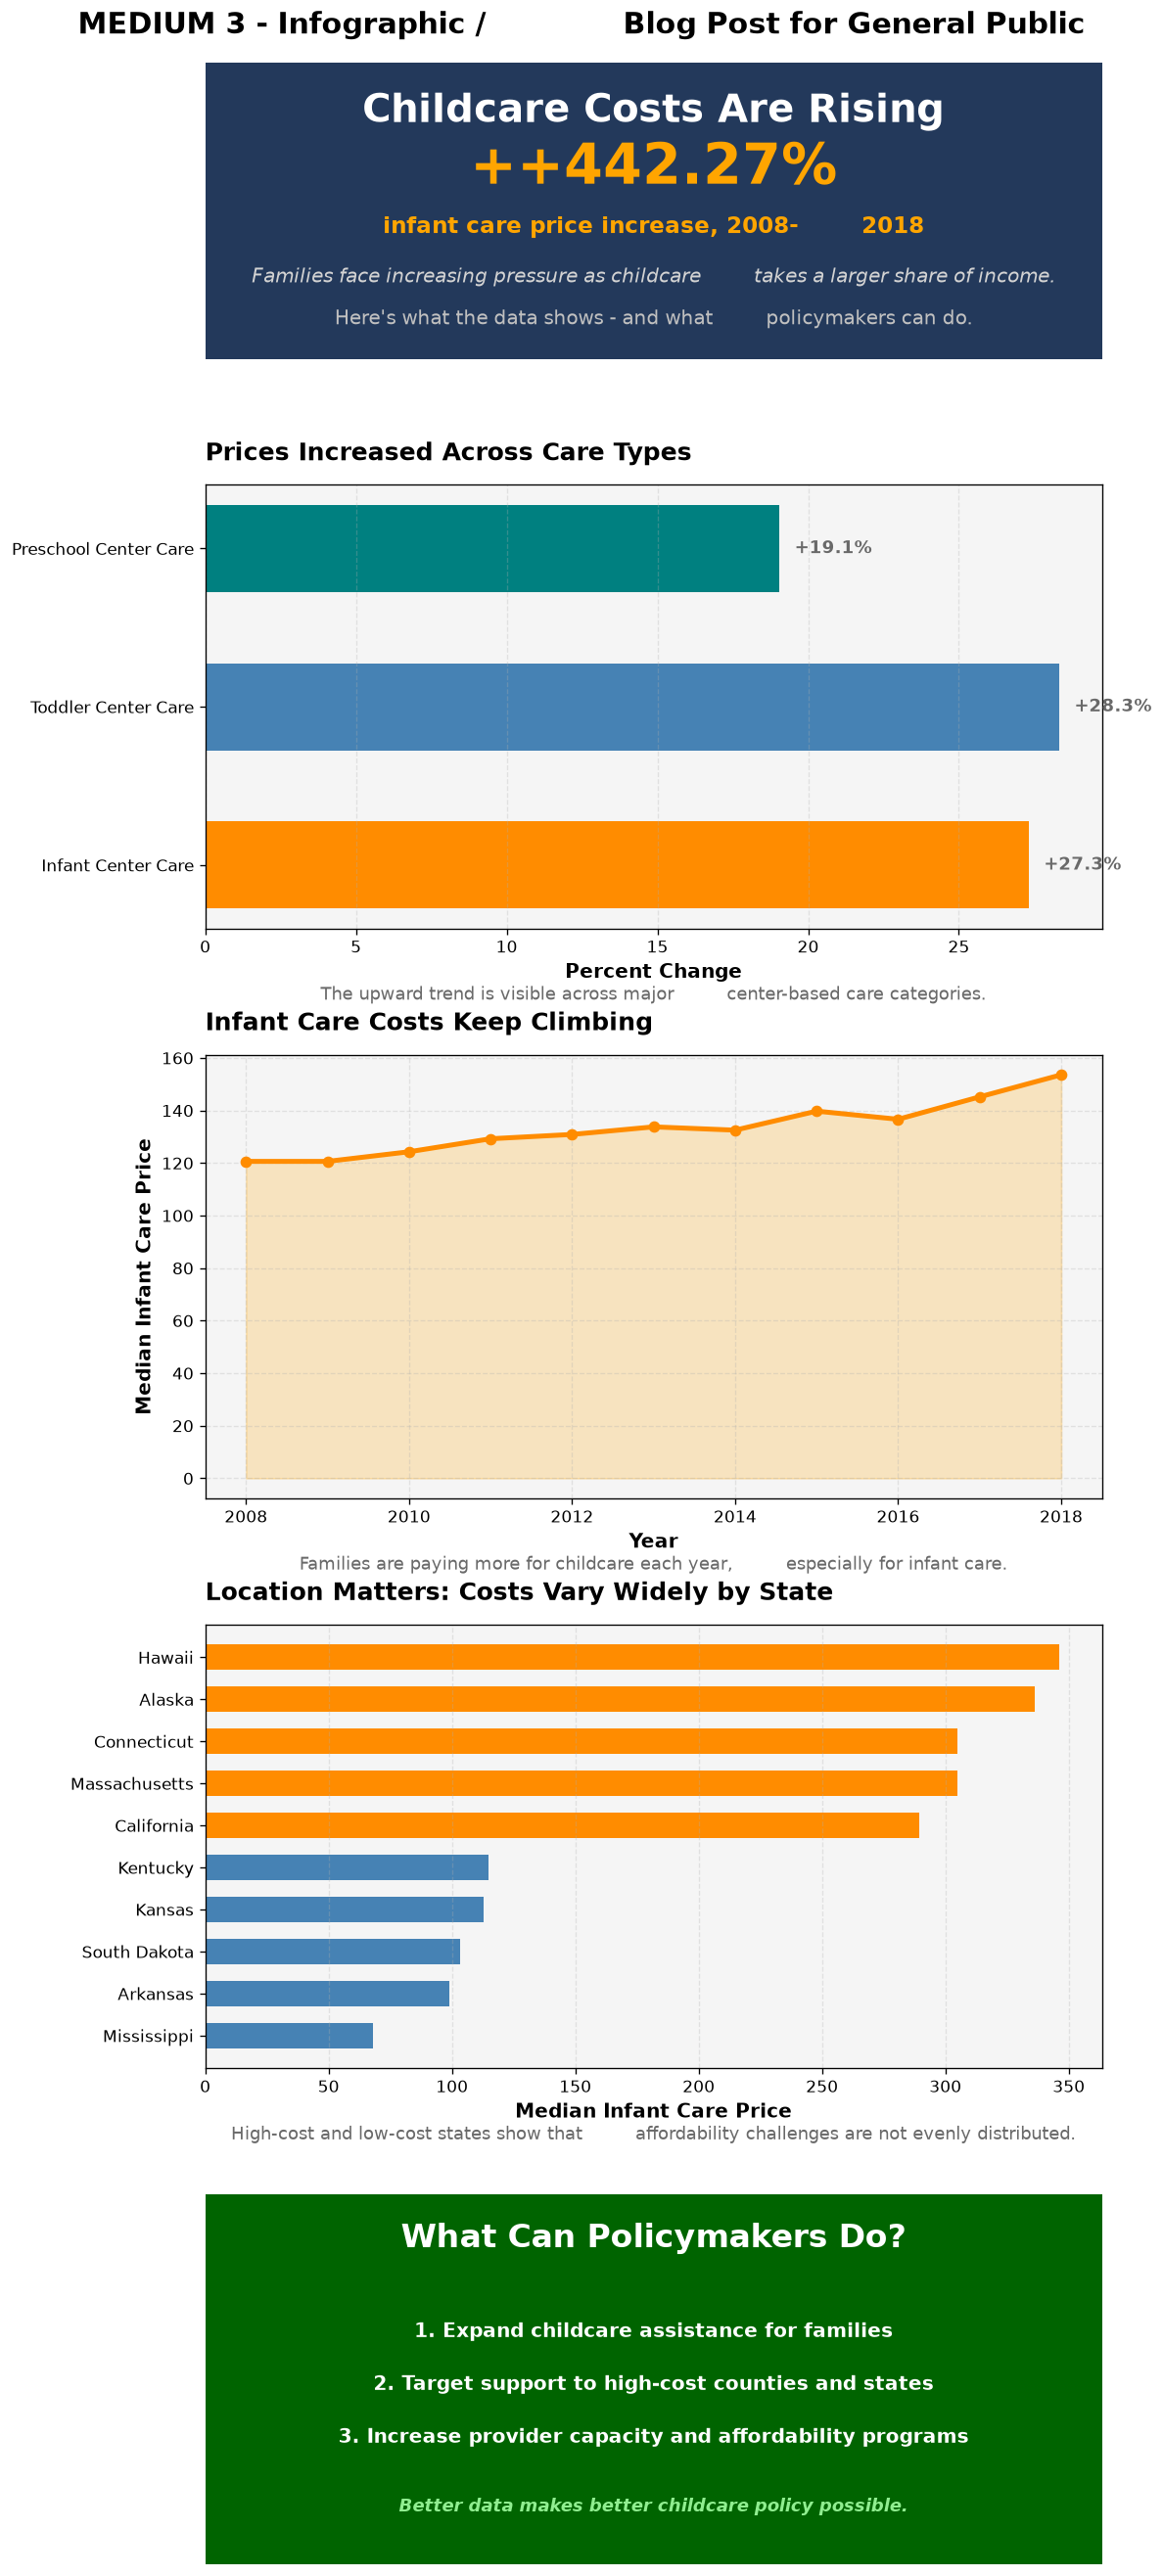

In [59]:
# =====================================================
# Medium 3: Infographic / Blog Post Mock-up
# =====================================================
fig, axes = plt.subplots(5, 1, figsize=(10, 22),\
                          gridspec_kw={'height_ratios': [2, 3, 3, 3, 2.5]})
fig.patch.set_facecolor('white')
fig.suptitle('MEDIUM 3 - Infographic / \
             Blog Post for General Public', fontsize=18,\
                  fontweight='bold', y=0.995)

ax = axes[0]
ax.set_xlim(0, 10); ax.set_ylim(0, 6)
ax.set_facecolor('#23395B')
ax.text(5, 4.8, 'Childcare Costs Are Rising',\
         ha='center', fontsize=24, fontweight='bold', color='white')
ax.text(5, 3.55, f'+{(summary["end_infant"] - summary["start_infant"]):+,.2f}%',\
         ha='center', fontsize=34, color='orange', fontweight='bold')
ax.text(5, 2.55, f'infant care price increase, {summary["start_year"]}-\
        {summary["end_year"]}', ha='center', fontsize=14, \
            color='orange', fontweight='bold')
ax.text(5, 1.55, 'Families face increasing pressure as childcare\
         takes a larger share of income.', ha='center', \
            fontsize=12, color='lightgray', style='italic')
ax.text(5, 0.7, "Here's what the data shows - and what \
        policymakers can do.", ha='center', fontsize=12, color='silver')
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax = axes[1]
care_names = changes_df['metric'].tolist()
pct_vals = changes_df['pct_change'].tolist()
bar_colors = ['darkorange', 'steelblue', 'teal'][:len(care_names)]
bars = ax.barh(care_names, pct_vals, color=bar_colors, height=0.55)
ax.set_title('Prices Increased Across Care Types',\
              fontsize=15, fontweight='bold', pad=15, loc='left')
ax.set_xlabel('Percent Change', fontsize=12, fontweight='bold')
for bar, val in zip(bars, pct_vals):
    ax.text(bar.get_width() + 0.5, bar.get_y() + \
            bar.get_height()/2, f'+{val:.1f}%', va='center', \
                fontsize=11, fontweight='bold', color='dimgray')
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_facecolor('whitesmoke')
ax.text(0.5, -0.16, 'The upward trend is visible across major\
         center-based care categories.', ha='center', \
            fontsize=11, color='dimgray', transform=ax.transAxes)

ax = axes[2]
ax.plot(yearly_medians[year_col], yearly_medians[infant_col],\
         color='darkorange', linewidth=3, marker='o')
ax.fill_between(yearly_medians[year_col], yearly_medians[infant_col],\
                 alpha=0.22, color='orange')
ax.set_title('Infant Care Costs Keep Climbing', fontsize=15,\
              fontweight='bold', pad=15, loc='left')
ax.set_xlabel('Year', fontsize=12, fontweight='bold')
ax.set_ylabel('Median Infant Care Price', fontsize=12,\
               fontweight='bold')
ax.grid(alpha=0.3, linestyle='--')
ax.set_facecolor('whitesmoke')
ax.annotate(f'${summary["end_infant"]:,.0f}({final_year})',\
             xy=(final_year, summary["end_infant"]), xytext=(final_year - 2,\
                     summary["end_infant"] * 1.03),
            fontsize=11, fontweight='bold', color='darkorange',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='darkorange'),
            arrowprops=dict(arrowstyle='->', color='darkorange', lw=2))
ax.text(0.5, -0.16, 'Families are paying more for childcare each year, \
        especially for infant care.', ha='center', fontsize=11,\
              color='dimgray', transform=ax.transAxes)

ax = axes[3]
combined = pd.concat([top_states, bottom_states]).sort_values()
colors = ['darkorange' if state in top_states.index \
          else 'steelblue' for state in combined.index]
ax.barh(combined.index.astype(str), combined.values,\
         color=colors, height=0.6)
ax.set_title('Location Matters: Costs Vary Widely by State',\
              fontsize=15, fontweight='bold', pad=15, loc='left')
ax.set_xlabel('Median Infant Care Price', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_facecolor('whitesmoke')
ax.text(0.5, -0.16, 'High-cost and low-cost states show that \
        affordability challenges are not evenly distributed.', \
        ha='center', fontsize=11, color='dimgray', transform=ax.transAxes)

ax = axes[4]
ax.set_xlim(0, 10); ax.set_ylim(0, 7)
ax.set_facecolor('darkgreen')
ax.text(5, 6.0, 'What Can Policymakers Do?', ha='center',\
         fontsize=20, fontweight='bold', color='white')
actions = [
    '1. Expand childcare assistance for families',
    '2. Target support to high-cost counties and states',
    '3. Increase provider capacity and affordability programs'
]
for k, action in enumerate(actions):
    ax.text(5, 4.3 - k * 1.0, action, ha='center', fontsize=12,\
             color='white', fontweight='bold')
ax.text(5, 1.0, 'Better data makes better childcare policy possible.',\
         ha='center', fontsize=11, color='lightgreen', style='italic', fontweight='bold')
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
#plt.savefig('medium3_infographic_final.png', dpi=200, bbox_inches='tight')
plt.show()